# GCI World 2026 September - Final Assignment
**Angela Espinoza** - Company A churn: who to contact, based on expected value.

Run all cells in order. Needs `Client.csv` and `Record.csv` in `telecom/` or `data/`. Libraries: pandas, numpy, scikit-learn, lightgbm, xgboost, shap, matplotlib. Seed = 42.

Generative AI disclosure: code, analysis and charts were developed with Claude Code (Anthropic).

## 0. Setup
Data split 60/20/20 (train / validation / test), stratified by churn.

In [1]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

SEED = 42
# Carpeta de datos: telecom/ (como en el tutorial) o data/
ROOT = Path.cwd()
DATA = next(p for p in [ROOT / "telecom", ROOT / "data", ROOT.parent / "data"] if (p / "Client.csv").exists())
RES, FIGS = ROOT / "results", ROOT / "figures"
for p in (RES, FIGS):
    p.mkdir(parents=True, exist_ok=True)


def load():
    client = pd.read_csv(DATA / "Client.csv")
    record = pd.read_csv(DATA / "Record.csv")
    return record.merge(client, on="Customer_ID", how="inner")


def split(df):
    # 60/20/20 estratificado: entrenamiento, validacion (elegir todo) y prueba (se evalua una vez)
    y = df["churn"]
    tr, tmp = train_test_split(df.index, test_size=0.4, random_state=SEED, stratify=y)
    va, te = train_test_split(tmp, test_size=0.5, random_state=SEED, stratify=y.loc[tmp])
    return tr, va, te


def features(df):
    return df.drop(columns=["churn", "Customer_ID"])


def to_codes(X, ref):
    # Categorias a enteros usando solo las categorias vistas en entrenamiento
    X = X.copy()
    for c in X.select_dtypes(include="object").columns:
        cats = {v: i for i, v in enumerate(sorted(ref[c].dropna().unique()))}
        X[c] = X[c].map(cats)
    return X


def boot_auc_diff(y, p_a, p_b, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        diffs.append(roc_auc_score(y[i], p_a[i]) - roc_auc_score(y[i], p_b[i]))
    return np.percentile(diffs, [2.5, 97.5])

## 1. Leakage check and model comparison
Choices are made on validation; test is used for reporting. Gain over the baseline has a 95% bootstrap interval.

In [2]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


df = load()
tr, va, te = split(df)
X = features(df)
y = df["churn"].values
Xtr, Xva, Xte = X.loc[tr], X.loc[va], X.loc[te]
ytr, yva, yte = y[tr], y[va], y[te]
print("tamanos:", len(tr), len(va), len(te), "| churn:", y.mean().round(3))

# ---- Revision de fuga: AUC de cada variable por separado (en entrenamiento) ----
Xc = to_codes(Xtr, Xtr)
single = {}
for c in Xc.columns:
    v = Xc[c].fillna(Xc[c].median())
    a = roc_auc_score(ytr, v)
    single[c] = max(a, 1 - a)
leak = pd.Series(single).sort_values(ascending=False)
leak.head(15).round(4).to_csv(RES / "single_feature_auc_top15.csv", header=["auc"])
print("Top AUC por variable sola:\n", leak.head(8).round(3).to_string())

# ---- Modelos ----
num = Xtr.select_dtypes(exclude="object").columns.tolist()
cat = Xtr.select_dtypes(include="object").columns.tolist()


def lr_pipe(cols_num, cols_cat, C=1.0):
    pre = ColumnTransformer([
        ("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), cols_num),
        ("c", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("o", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200))]), cols_cat),
    ])
    return Pipeline([("pre", pre), ("m", LogisticRegression(C=C, max_iter=2000, random_state=SEED))])


preds = {}
# Base simple: regresion logistica con 5 variables de negocio
base_cols = ["eqpdays", "months", "mou_Mean", "rev_Mean", "change_mou"]
base = lr_pipe(base_cols, []).fit(Xtr[base_cols], ytr)
preds["Baseline: logistic regression (5 features)"] = (base.predict_proba(Xva[base_cols])[:, 1],
                                                       base.predict_proba(Xte[base_cols])[:, 1])

# Regresion logistica completa: C elegido en validacion
best = None
for C in [0.01, 0.1, 1.0]:
    m = lr_pipe(num, cat, C).fit(Xtr, ytr)
    a = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
    print("LR C=", C, "val AUC", round(a, 4))
    if best is None or a > best[0]:
        best = (a, m, C)
m = best[1]
preds["Logistic regression (all features)"] = (m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1])

# LightGBM y XGBoost: arboles y parada temprana con validacion
Ctr, Cva, Cte = to_codes(Xtr, Xtr), to_codes(Xva, Xtr), to_codes(Xte, Xtr)
lg = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
                        random_state=SEED, n_jobs=-1, verbose=-1)
lg.fit(Ctr, ytr, eval_set=[(Cva, yva)], eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
preds["LightGBM"] = (lg.predict_proba(Cva)[:, 1], lg.predict_proba(Cte)[:, 1])
print("LightGBM arboles:", lg.best_iteration_)

xg = XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=5, min_child_weight=10, subsample=0.8,
                   colsample_bytree=0.6, reg_lambda=5.0, tree_method="hist", eval_metric="auc",
                   early_stopping_rounds=100, random_state=SEED, n_jobs=-1)
xg.fit(Ctr, ytr, eval_set=[(Cva, yva)], verbose=False)
preds["XGBoost"] = (xg.predict_proba(Cva)[:, 1], xg.predict_proba(Cte)[:, 1])
print("XGBoost arboles:", xg.best_iteration + 1)


def lift_at(y_true, p, frac):
    k = int(len(p) * frac)
    top = np.argsort(-p)[:k]
    return y_true[top].mean() / y_true.mean()


rows = []
for name, (pv, pt) in preds.items():
    rows.append({"model": name, "val_auc": roc_auc_score(yva, pv), "test_auc": roc_auc_score(yte, pt),
                 "test_logloss": log_loss(yte, pt), "test_brier": brier_score_loss(yte, pt),
                 "test_lift_top10": lift_at(yte, pt, 0.10), "test_lift_top20": lift_at(yte, pt, 0.20)})
res = pd.DataFrame(rows)

# Mejora frente al baseline con intervalo de confianza al 95% (bootstrap pareado en prueba)
b = preds["Baseline: logistic regression (5 features)"][1]
lo_hi = {k: boot_auc_diff(yte, v[1], b) for k, v in preds.items() if not k.startswith("Baseline")}
res["auc_gain_vs_baseline_ci95"] = res["model"].map(
    lambda k: "" if k.startswith("Baseline") else f"[{lo_hi[k][0]:+.4f}, {lo_hi[k][1]:+.4f}]")
res.round(4).to_csv(RES / "model_comparison.csv", index=False)
print(res.round(4).to_string())

# Guardar predicciones para los pasos de calibracion y valor esperado
out_va = pd.DataFrame({"Customer_ID": df.loc[va, "Customer_ID"].values, "churn": yva})
out_te = pd.DataFrame({"Customer_ID": df.loc[te, "Customer_ID"].values, "churn": yte})
for name, (pv, pt) in preds.items():
    out_va[name] = pv
    out_te[name] = pt
out_va.to_csv(RES / "preds_val.csv", index=False)
out_te.to_csv(RES / "preds_test.csv", index=False)
print("listo")

tamanos: 60000 20000 20000 | churn: 0.496


Top AUC por variable sola:
 eqpdays            0.575
hnd_price          0.560
totmrc_Mean        0.543
mou_opkv_Mean      0.539
mou_cvce_Mean      0.539
mou_Mean           0.538
iwylis_vce_Mean    0.535
mouiwylisv_Mean    0.534


LR C= 0.01 val AUC 0.6267


LR C= 0.1 val AUC 0.6265


LR C= 1.0 val AUC 0.6262


LightGBM arboles: 717


XGBoost arboles: 899


                                        model  val_auc  test_auc  test_logloss  test_brier  test_lift_top10  test_lift_top20 auc_gain_vs_baseline_ci95
0  Baseline: logistic regression (5 features)   0.5786    0.5730        0.6852      0.2460           1.1996           1.1370                          
1          Logistic regression (all features)   0.6267    0.6285        0.6686      0.2378           1.3499           1.2949        [+0.0483, +0.0626]
2                                    LightGBM   0.7001    0.6926        0.6317      0.2211           1.5991           1.4785        [+0.1117, +0.1282]
3                                     XGBoost   0.6995    0.6930        0.6317      0.2211           1.5940           1.4815        [+0.1120, +0.1285]
listo


## 2. EDA, calibration, gain curve, SHAP and expected value
Margin (30%), horizon (12 months), offer cost and success rate are **assumptions**, not measured in the data.

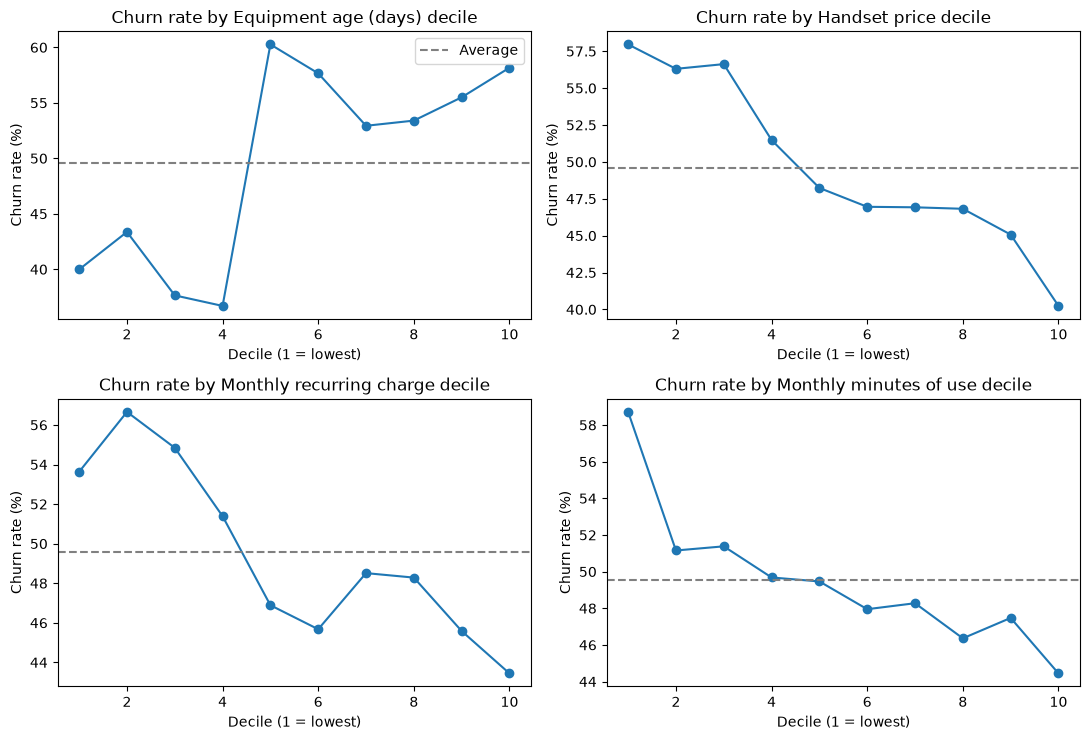

                           version   brier  logloss
0                     LightGBM raw  0.2211   0.6317
1  LightGBM + isotonic calibration  0.2213   0.6349


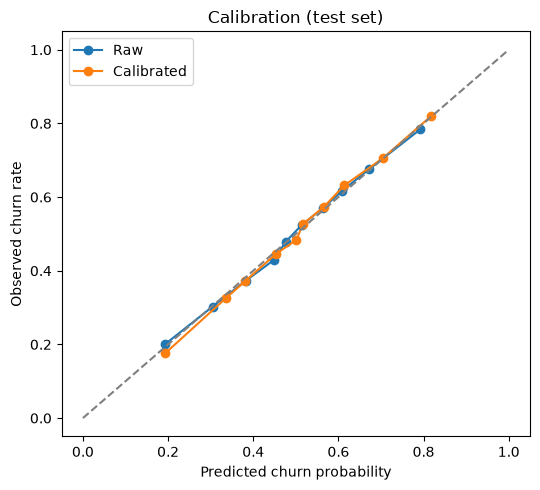

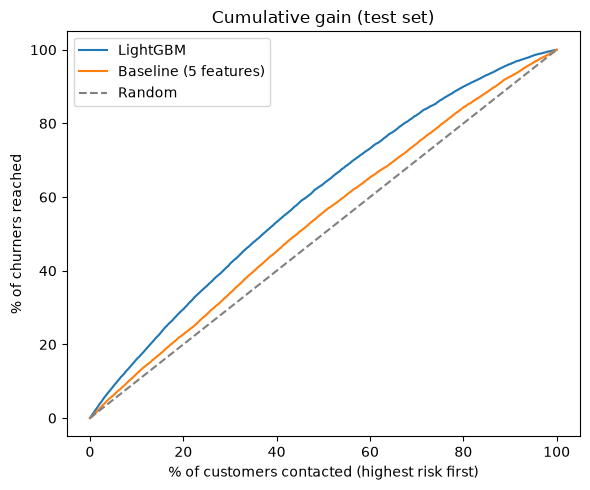

eqpdays          0.2469
months           0.1815
change_mou       0.1673
mou_Mean         0.1511
uniqsubs         0.0959
totmrc_Mean      0.0847
hnd_price        0.0822
drop_vce_Mean    0.0753
avgmou           0.0734
lor              0.0728
dtype: float64


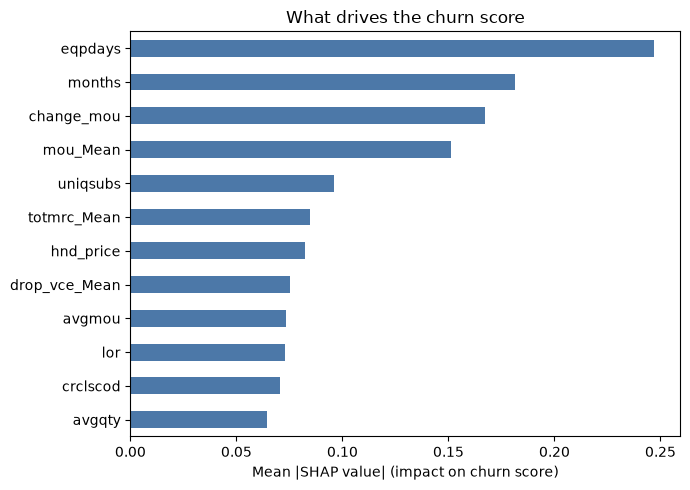

Caso base: s=0.20, costo=15, margen=0.30, horizonte=12 meses
                        policy  net_benefit_per_1000_customers  customers_contacted_%
                Contact nobody                             0.0                    0.0
              Contact everyone                          5618.9                  100.0
     Top 20% by baseline model                          1771.3                   20.0
           Top 20% by LightGBM                          2674.5                   20.0
Expected-value rule (LightGBM)                          8118.0                   54.3


IC95 ganancia por 1000 clientes de la regla: {'vs_contact_everyone': array([2374., 2634.]), 'vs_baseline_top20': array([6027., 6661.])}
      0.05    0.10     0.20     0.30
5   1465.0  5739.0  15725.0  25960.0
10   464.0  2929.0  11478.0  21368.0
15   195.0  1590.0   8118.0  17217.0
25    55.0   590.0   4226.0  10926.0
40    19.0   236.0   1854.0   5687.0


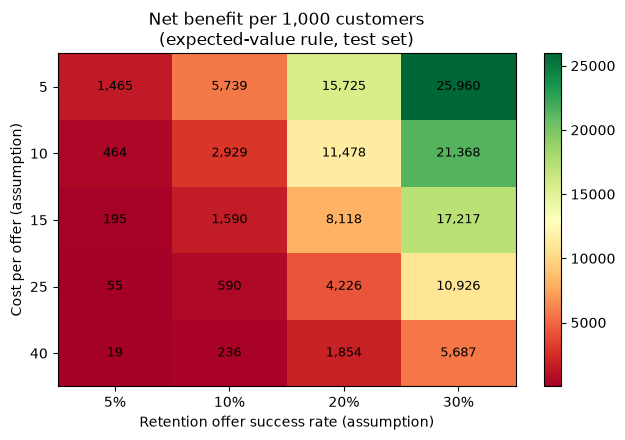

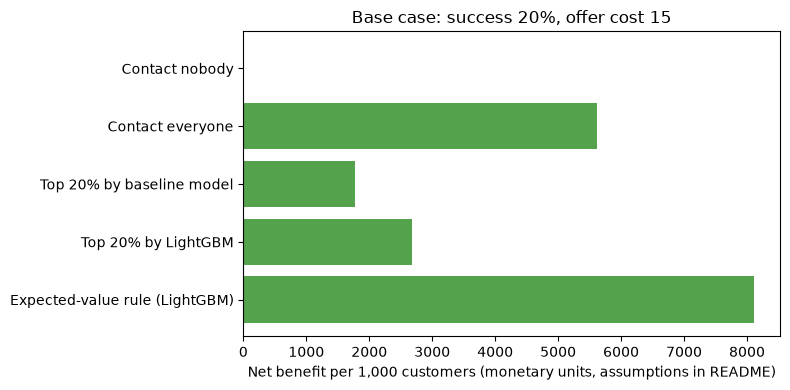

listo


In [3]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss


df = load()
tr, va, te = split(df)
pv = pd.read_csv(RES / "preds_val.csv")
pt = pd.read_csv(RES / "preds_test.csv")
LG, BASE = "LightGBM", "Baseline: logistic regression (5 features)"
yva, yte = pv["churn"].values, pt["churn"].values
rev_te = pt[["Customer_ID"]].merge(df[["Customer_ID", "rev_Mean"]], on="Customer_ID")["rev_Mean"].fillna(df.loc[tr, "rev_Mean"].median()).values

# ---------- 1. EDA: tasa de churn por decil de las variables con mas senal ----------
d = df.loc[tr]
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
for a, (col, lab) in zip(ax.ravel(), [("eqpdays", "Equipment age (days)"),
                                      ("hnd_price", "Handset price"),
                                      ("totmrc_Mean", "Monthly recurring charge"),
                                      ("mou_Mean", "Monthly minutes of use")]):
    q = pd.qcut(d[col].rank(method="first"), 10, labels=False)
    rate = d.groupby(q)["churn"].mean() * 100
    a.plot(range(1, 11), rate.values, marker="o")
    a.axhline(d["churn"].mean() * 100, color="gray", linestyle="--", label="Average")
    a.set_title(f"Churn rate by {lab} decile")
    a.set_xlabel("Decile (1 = lowest)")
    a.set_ylabel("Churn rate (%)")
ax[0, 0].legend()
plt.tight_layout()
plt.savefig(FIGS / "eda_drivers.png", dpi=150)
plt.show()

# ---------- 2. Calibracion (isotonica ajustada en validacion, evaluada en prueba) ----------
iso = IsotonicRegression(out_of_bounds="clip").fit(pv[LG], yva)
cal_te = iso.predict(pt[LG])
cal_rows = [{"version": "LightGBM raw", "brier": brier_score_loss(yte, pt[LG]), "logloss": log_loss(yte, pt[LG])},
            {"version": "LightGBM + isotonic calibration",
             "brier": brier_score_loss(yte, cal_te), "logloss": log_loss(yte, np.clip(cal_te, 1e-6, 1 - 1e-6))}]
pd.DataFrame(cal_rows).round(4).to_csv(RES / "calibration.csv", index=False)
print(pd.DataFrame(cal_rows).round(4))
fig, ax = plt.subplots(figsize=(5.5, 5))
for lab, p in [("Raw", pt[LG].values), ("Calibrated", cal_te)]:
    fx, fy = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    ax.plot(fx, fy, marker="o", label=lab)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("Predicted churn probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration (test set)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "calibration.png", dpi=150)
plt.show()

# ---------- 3. Curva de ganancia ----------
fig, ax = plt.subplots(figsize=(6, 5))
n = len(yte)
for lab, p in [("LightGBM", pt[LG].values), ("Baseline (5 features)", pt[BASE].values)]:
    order = np.argsort(-p)
    gain = np.cumsum(yte[order]) / yte.sum() * 100
    ax.plot(np.arange(1, n + 1) / n * 100, gain, label=lab)
ax.plot([0, 100], [0, 100], "--", color="gray", label="Random")
ax.set_xlabel("% of customers contacted (highest risk first)")
ax.set_ylabel("% of churners reached")
ax.set_title("Cumulative gain (test set)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "gain_curve.png", dpi=150)
plt.show()

# ---------- 4. SHAP del LightGBM (mismo ajuste que run_models.py) ----------
X = features(df)
Ctr, Cva, Cte = to_codes(X.loc[tr], X.loc[tr]), to_codes(X.loc[va], X.loc[tr]), to_codes(X.loc[te], X.loc[tr])
lg = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
                        random_state=SEED, n_jobs=-1, verbose=-1)
lg.fit(Ctr, df.loc[tr, "churn"], eval_set=[(Cva, df.loc[va, "churn"])], eval_metric="auc",
       callbacks=[lgb.early_stopping(100, verbose=False)])
samp = Cte.sample(8000, random_state=SEED)
sv = shap.TreeExplainer(lg).shap_values(samp)
if isinstance(sv, list):
    sv = sv[1]
if sv.ndim == 3:
    sv = sv[:, :, 1]
imp = pd.Series(np.abs(sv).mean(axis=0), index=samp.columns).sort_values(ascending=False)
imp.head(15).round(4).to_csv(RES / "shap_top15.csv", header=["mean_abs_shap"])
print(imp.head(10).round(4))
plt.figure(figsize=(7, 5))
imp.head(12)[::-1].plot.barh(color="#4c78a8")
plt.xlabel("Mean |SHAP value| (impact on churn score)")
plt.title("What drives the churn score")
plt.tight_layout()
plt.savefig(FIGS / "shap_bar.png", dpi=150)
plt.show()

# ---------- 5. Valor esperado y punto de corte ----------
# SUPUESTOS (no medidos en los datos): margen, horizonte, costo de oferta y exito de retencion.
MARGIN, HORIZON = 0.30, 12


def policy_benefit(y, p_rank, value, target, s, c):
    return float(np.sum(y[target] * s * value[target]) - c * target.sum())


value = rev_te * MARGIN * HORIZON


def evaluate(s, c):
    thr_rule = (pt[LG].values * s * value - c) > 0
    k20 = int(0.2 * n)
    top20_lg = np.zeros(n, bool); top20_lg[np.argsort(-pt[LG].values)[:k20]] = True
    top20_bs = np.zeros(n, bool); top20_bs[np.argsort(-pt[BASE].values)[:k20]] = True
    everyone = np.ones(n, bool)
    pol = {"Contact nobody": np.zeros(n, bool), "Contact everyone": everyone,
           "Top 20% by baseline model": top20_bs, "Top 20% by LightGBM": top20_lg,
           "Expected-value rule (LightGBM)": thr_rule}
    return {k: policy_benefit(yte, None, value, m, s, c) / n * 1000 for k, m in pol.items()}, pol


S0, C0 = 0.20, 15.0
base_res, pols = evaluate(S0, C0)
pol_df = pd.DataFrame({"policy": list(base_res), "net_benefit_per_1000_customers": list(base_res.values()),
                       "customers_contacted_%": [pols[k].mean() * 100 for k in base_res]})
pol_df.round(1).to_csv(RES / "policy_comparison_base_case.csv", index=False)
print("Caso base: s=%.2f, costo=%.0f, margen=%.2f, horizonte=%d meses" % (S0, C0, MARGIN, HORIZON))
print(pol_df.round(1).to_string(index=False))

# Intervalo de confianza (bootstrap) de la ganancia de la regla de valor esperado vs contactar a todos
rng = np.random.default_rng(SEED)
rule = pols["Expected-value rule (LightGBM)"]
bs20 = pols["Top 20% by baseline model"]
diff_all, diff_base = [], []
for _ in range(1000):
    i = rng.integers(0, n, n)
    f = lambda m: (np.sum(yte[i] * S0 * value[i] * m[i]) - C0 * m[i].sum()) / n * 1000
    diff_all.append(f(rule) - f(pols["Contact everyone"]))
    diff_base.append(f(rule) - f(bs20))
ci = {"vs_contact_everyone": np.percentile(diff_all, [2.5, 97.5]),
      "vs_baseline_top20": np.percentile(diff_base, [2.5, 97.5])}
pd.DataFrame({k: [f"[{v[0]:.0f}, {v[1]:.0f}]"] for k, v in ci.items()}).to_csv(RES / "ev_rule_gain_ci95.csv", index=False)
print("IC95 ganancia por 1000 clientes de la regla:", {k: np.round(v, 0) for k, v in ci.items()})

# Sensibilidad: ganancia de la regla frente a "contactar a todos" segun exito y costo
S_grid, C_grid = [0.05, 0.10, 0.20, 0.30], [5, 10, 15, 25, 40]
sens = pd.DataFrame(index=C_grid, columns=S_grid, dtype=float)
for c in C_grid:
    for s in S_grid:
        r, _ = evaluate(s, c)
        sens.loc[c, s] = r["Expected-value rule (LightGBM)"]
sens.round(0).to_csv(RES / "sensitivity_net_benefit_per_1000.csv")
print(sens.round(0))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(sens.values.astype(float), cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(S_grid)))
ax.set_xticklabels([f"{int(s * 100)}%" for s in S_grid])
ax.set_yticks(range(len(C_grid)))
ax.set_yticklabels(C_grid)
for i in range(len(C_grid)):
    for j in range(len(S_grid)):
        ax.text(j, i, f"{sens.values[i, j]:,.0f}", ha="center", va="center", fontsize=9)
ax.set_xlabel("Retention offer success rate (assumption)")
ax.set_ylabel("Cost per offer (assumption)")
ax.set_title("Net benefit per 1,000 customers\n(expected-value rule, test set)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(FIGS / "ev_sensitivity.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pol_df["policy"][::-1], pol_df["net_benefit_per_1000_customers"][::-1], color="#54a24b")
ax.set_xlabel("Net benefit per 1,000 customers (monetary units, assumptions in README)")
ax.set_title("Base case: success 20%, offer cost 15")
plt.tight_layout()
plt.savefig(FIGS / "policy_comparison.png", dpi=150)
plt.show()
print("listo")

## 3. Realistic churn scenarios
The data has about 50% churn. This section re-weights the test set to lower churn rates, assuming only the churn proportion changes and the model ranking holds.

Ganancia por 1000 clientes (exito 20 %, costo 15):
 churn_rate_%  contact_everyone  top_10pct  ev_rule  ev_rule_contacted_%  breakeven_offer_cost_top10
         1.00         -14583.97   -1390.56     0.00                 0.00                        1.09
         2.00         -14167.94   -1282.85     2.19                 0.01                        2.16
         5.00         -12919.84    -979.42    27.11                 0.47                        5.20
        49.56           5618.57    1403.37  8117.73                54.28                       29.03
Churn 2 %: ganancia por 1000 (filas costo, columnas exito)
       0.05   0.10   0.20   0.30
0.5   22.0  116.0  432.0  809.0
1.0    8.0   43.0  232.0  517.0
2.0    2.0   15.0   87.0  249.0
5.0    0.0    1.0   20.0   56.0
15.0   0.0    0.0    2.0    4.0
Churn 2 %: % de clientes contactados
       0.05  0.10  0.20  0.30
0.5    8.3  25.7  54.7  71.0
1.0    1.6   8.3  25.7  42.3
2.0    0.2   1.6   8.3  16.6
5.0    0.0   0.1   0.8   2.7
15.0   0.

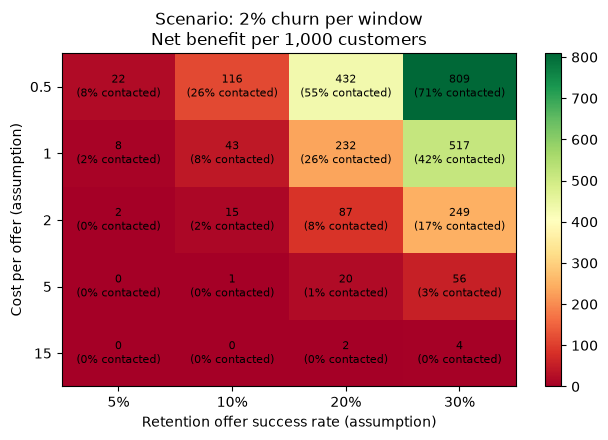

listo


In [4]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt


df = load()
pt = pd.read_csv(RES / "preds_test.csv")
y = pt["churn"].values
p = pt["LightGBM"].values
rev = pt[["Customer_ID"]].merge(df[["Customer_ID", "rev_Mean"]], on="Customer_ID")["rev_Mean"]
rev = rev.fillna(df["rev_Mean"].median()).values
value = rev * 0.30 * 12          # supuesto: margen 30 %, horizonte 12 meses
base_prev = y.mean()
n = len(y)


def scenario(prev):
    # Supuesto: solo cambia la proporcion de churn; el orden del modelo se mantiene
    odds = p / (1 - p) * (prev / (1 - prev)) / (base_prev / (1 - base_prev))
    p_adj = odds / (1 + odds)
    w = np.where(y == 1, prev / base_prev, (1 - prev) / (1 - base_prev))
    return p_adj, w


def benefit(target, w, s, c):
    return float(np.sum(w * target * (y * s * value - c)) / w.sum() * 1000)


def top_share(p_adj, w, share):
    order = np.argsort(-p_adj)
    chosen = np.cumsum(w[order]) / w.sum() <= share
    m = np.zeros(n, bool)
    m[order[chosen]] = True
    return m


S0, C0 = 0.20, 15.0
rows = []
for prev in [0.01, 0.02, 0.05, base_prev]:
    p_adj, w = scenario(prev)
    rule = p_adj * S0 * value > C0
    top10 = top_share(p_adj, w, 0.10)
    rows.append({"churn_rate_%": prev * 100,
                 "contact_everyone": benefit(np.ones(n, bool), w, S0, C0),
                 "top_10pct": benefit(top10, w, S0, C0),
                 "ev_rule": benefit(rule, w, S0, C0),
                 "ev_rule_contacted_%": float(np.sum(w * rule) / w.sum() * 100),
                 "breakeven_offer_cost_top10": float(np.sum(w * top10 * y * S0 * value) / np.sum(w * top10))})
scen = pd.DataFrame(rows)
scen.round(2).to_csv(RES / "prevalence_scenarios.csv", index=False)
print("Ganancia por 1000 clientes (exito 20 %, costo 15):")
print(scen.round(2).to_string(index=False))

# Escenario de churn mensual 2 %: que costo de oferta tiene sentido
p_adj, w = scenario(0.02)
S_grid, C_grid = [0.05, 0.10, 0.20, 0.30], [0.5, 1, 2, 5, 15]
ben = pd.DataFrame([[benefit(p_adj * s * value > c, w, s, c) for s in S_grid] for c in C_grid],
                   index=C_grid, columns=S_grid)
share = pd.DataFrame([[np.sum(w * (p_adj * s * value > c)) / w.sum() * 100 for s in S_grid] for c in C_grid],
                     index=C_grid, columns=S_grid)
ben.round(1).to_csv(RES / "prev2_net_benefit_per_1000.csv")
share.round(1).to_csv(RES / "prev2_contacted_pct.csv")
print("Churn 2 %: ganancia por 1000 (filas costo, columnas exito)\n", ben.round(0))
print("Churn 2 %: % de clientes contactados\n", share.round(1))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(ben.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(S_grid)))
ax.set_xticklabels([f"{int(s * 100)}%" for s in S_grid])
ax.set_yticks(range(len(C_grid)))
ax.set_yticklabels(C_grid)
for i in range(len(C_grid)):
    for j in range(len(S_grid)):
        ax.text(j, i, f"{ben.values[i, j]:,.0f}\n({share.values[i, j]:.0f}% contacted)",
                ha="center", va="center", fontsize=8)
ax.set_xlabel("Retention offer success rate (assumption)")
ax.set_ylabel("Cost per offer (assumption)")
ax.set_title("Scenario: 2% churn per window\nNet benefit per 1,000 customers")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(FIGS / "prevalence_2pct.png", dpi=150)
plt.show()
print("listo")

## 4. Robustness and sensitive variables
Same pipeline on 5 different data splits (test sets overlap, so the spread is only indicative), and the model without `ethnic`, `income` and `marital`. Removing them does not guarantee fairness: other variables can act as proxies.

In [5]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


df = load()
X = features(df)
y = df["churn"].values
SENSITIVE = ["ethnic", "income", "marital"]
BASE_COLS = ["eqpdays", "months", "mou_Mean", "rev_Mean", "change_mou"]
S0, C0, MARGIN, HORIZON = 0.20, 15.0, 0.30, 12      # mismos supuestos del caso base


def split_seed(seed):
    tr, tmp = train_test_split(df.index, test_size=0.4, random_state=seed, stratify=df["churn"])
    va, te = train_test_split(tmp, test_size=0.5, random_state=seed, stratify=df.loc[tmp, "churn"])
    return tr, va, te


def fit_lgb(cols, tr, va, te):
    A = X[cols]
    Ctr, Cva, Cte = (to_codes(A.loc[i], A.loc[tr]) for i in (tr, va, te))
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0,
                           random_state=SEED, n_jobs=-1, verbose=-1)
    m.fit(Ctr, df.loc[tr, "churn"], eval_set=[(Cva, df.loc[va, "churn"])], eval_metric="auc",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict_proba(Cte)[:, 1]


rows, group_rows = [], []
for seed in [42, 1, 2, 3, 4]:
    tr, va, te = split_seed(seed)
    yte = df.loc[te, "churn"].values
    value = df.loc[te, "rev_Mean"].fillna(df.loc[tr, "rev_Mean"].median()).values * MARGIN * HORIZON
    n = len(yte)

    base = Pipeline([("pre", ColumnTransformer([("n", Pipeline([("i", SimpleImputer(strategy="median")),
                                                               ("s", StandardScaler())]), BASE_COLS)])),
                     ("m", LogisticRegression(max_iter=2000, random_state=SEED))])
    p_base = base.fit(X.loc[tr, BASE_COLS], df.loc[tr, "churn"]).predict_proba(X.loc[te, BASE_COLS])[:, 1]
    p_full = fit_lgb(list(X.columns), tr, va, te)
    p_fair = fit_lgb([c for c in X.columns if c not in SENSITIVE], tr, va, te)

    gain = lambda m: float(np.sum(yte[m] * S0 * value[m]) - C0 * m.sum()) / n * 1000
    rule_full = p_full * S0 * value > C0
    rule_fair = p_fair * S0 * value > C0
    top20_base = np.zeros(n, bool)
    top20_base[np.argsort(-p_base)[:int(0.2 * n)]] = True
    everyone = np.ones(n, bool)
    rows.append({"seed": seed,
                 "auc_baseline": roc_auc_score(yte, p_base),
                 "auc_lightgbm": roc_auc_score(yte, p_full),
                 "auc_without_sensitive": roc_auc_score(yte, p_fair),
                 "ev_rule": gain(rule_full), "ev_rule_without_sensitive": gain(rule_fair),
                 "contact_everyone": gain(everyone),
                 "rule_minus_everyone": gain(rule_full) - gain(everyone),
                 "rule_minus_baseline_top20": gain(rule_full) - gain(top20_base),
                 "same_decision_%": float(np.mean(rule_full == rule_fair) * 100)})
    if seed == SEED:
        grp = df.loc[te, "ethnic"].fillna("missing").values
        for g in pd.Series(grp).value_counts().loc[lambda s: s >= 500].index:
            m = grp == g
            group_rows.append({"ethnic_code": g, "customers": int(m.sum()), "churn_%": yte[m].mean() * 100,
                               "contacted_%_full": rule_full[m].mean() * 100,
                               "contacted_%_without_sensitive": rule_fair[m].mean() * 100,
                               "mean_value": value[m].mean()})
    print("semilla", seed, "lista")

res = pd.DataFrame(rows)
res.round(4).to_csv(RES / "robustness_by_seed.csv", index=False)
summary = res.drop(columns="seed").agg(["mean", "std", "min", "max"]).T
summary.round(4).to_csv(RES / "robustness_summary.csv")
groups = pd.DataFrame(group_rows)
groups.round(2).to_csv(RES / "contact_rate_by_ethnic_code.csv", index=False)
print(summary.round(4).to_string())
print(groups.round(2).to_string(index=False))
print("listo")

semilla 42 lista


semilla 1 lista


semilla 2 lista


semilla 3 lista


semilla 4 lista
                                mean       std        min        max
auc_baseline                  0.5774    0.0032     0.5730     0.5808
auc_lightgbm                  0.6979    0.0057     0.6926     0.7069
auc_without_sensitive         0.6969    0.0059     0.6913     0.7053
ev_rule                    8261.7880  195.0719  8073.7278  8560.7878
ev_rule_without_sensitive  8254.8439  191.6394  8052.9834  8548.2274
contact_everyone           5687.0790  144.5679  5541.6635  5920.7852
rule_minus_everyone        2574.7089   58.7088  2499.1307  2640.0026
rule_minus_baseline_top20  6446.0004  161.8072  6213.1528  6606.6465
same_decision_%              96.1670    0.2101    95.9900    96.4350
ethnic_code  customers  churn_%  contacted_%_full  contacted_%_without_sensitive  mean_value
          N       6796    48.54             53.43                          53.44      208.35
          H       2749    51.33             60.02                          59.37      227.69
          S    

## 5. Presentation charts
Visual versions of the results above, saved in `figures/visual/`.

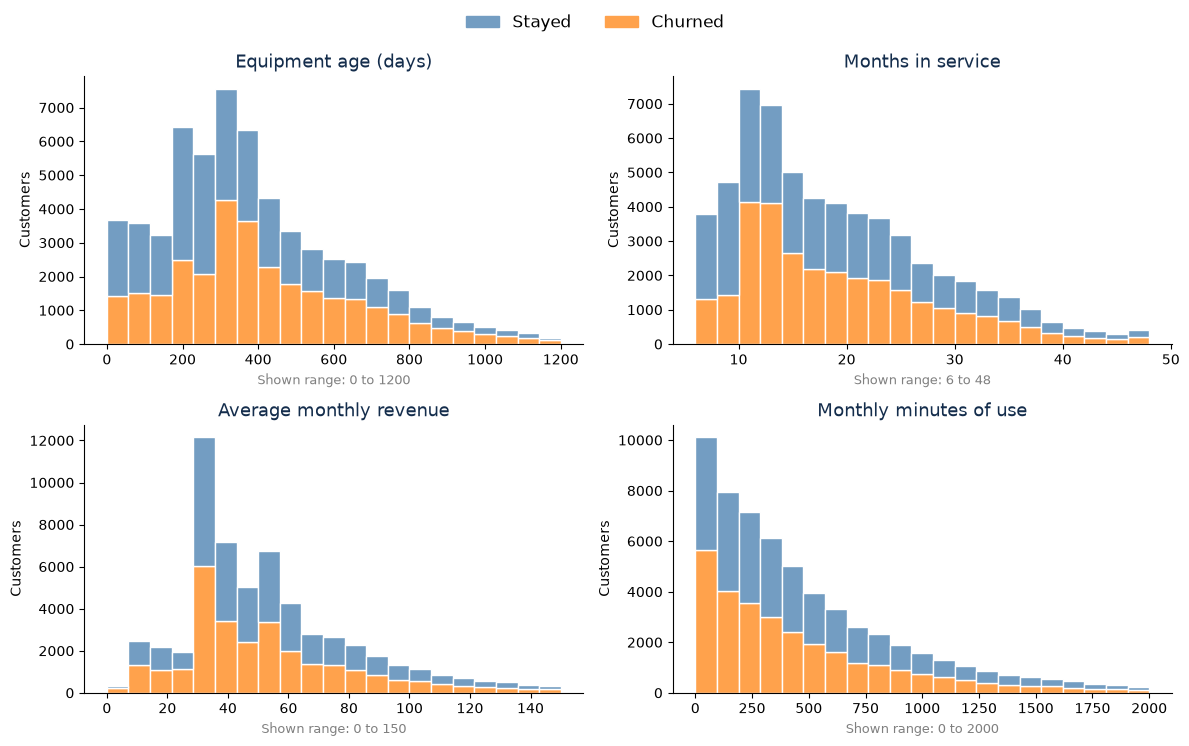

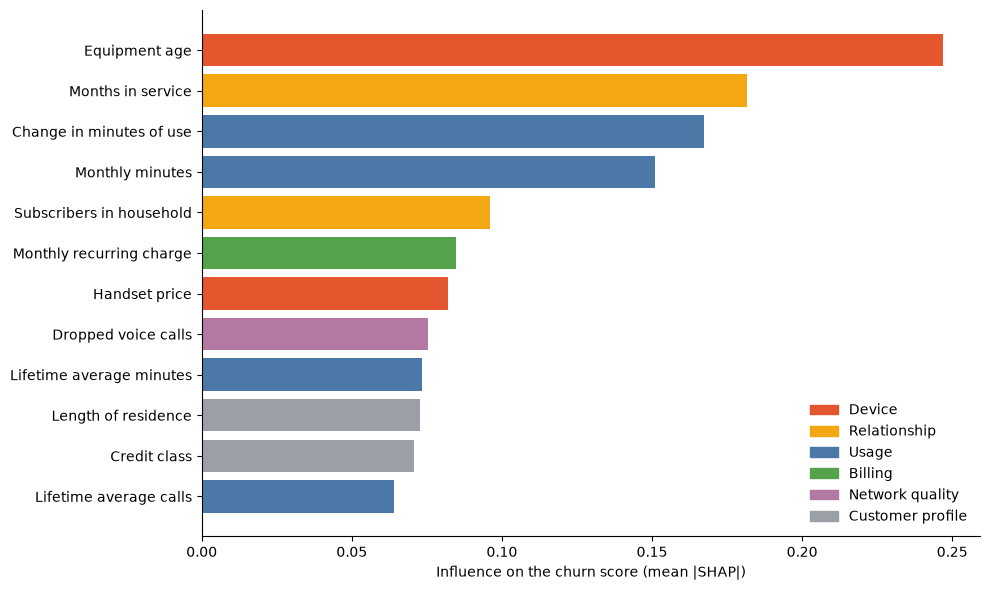

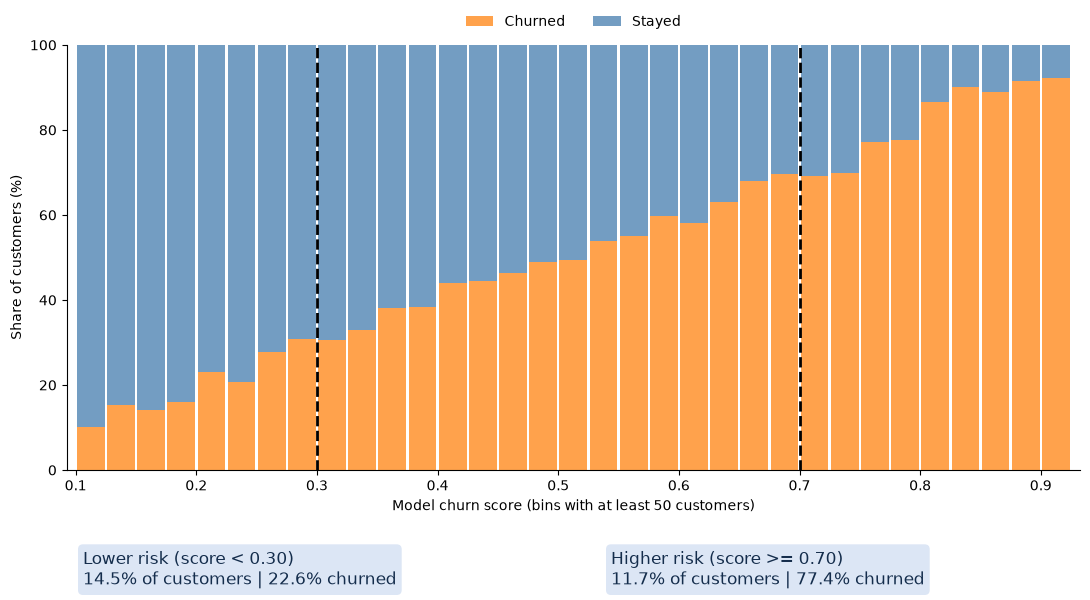

                          zone  customers_%  churned_%
0    Lower risk (score < 0.30)        14.50      22.55
1  Higher risk (score >= 0.70)        11.67      77.38


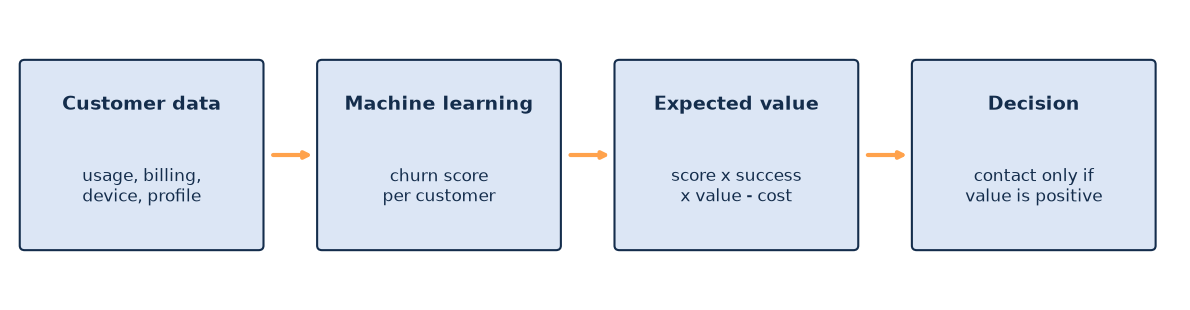

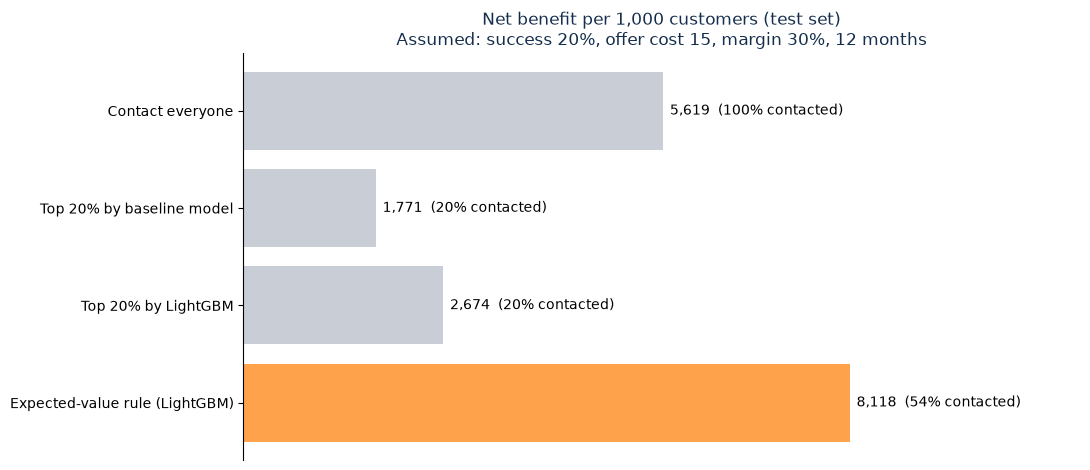

listo


In [6]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch


VIS = FIGS / "visual"
VIS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY, NAVY = "#739DC2", "#FFA24C", "#C9CED6", "#142D4C"
df = load()
tr, va, te = split(df)
d = df.loc[tr]


def clean_axes(a):
    a.spines[["top", "right"]].set_visible(False)


# 1. Quien se queda y quien se va, por variable (entrenamiento)
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
for a, (col, title, lo, hi) in zip(ax.ravel(), [
        ("eqpdays", "Equipment age (days)", 0, 1200), ("months", "Months in service", 6, 48),
        ("rev_Mean", "Average monthly revenue", 0, 150), ("mou_Mean", "Monthly minutes of use", 0, 2000)]):
    bins = np.linspace(lo, hi, 22)
    v = [d.loc[(d.churn == k) & d[col].between(lo, hi), col] for k in (1, 0)]
    a.hist(v, bins=bins, stacked=True, color=[ORANGE, BLUE], edgecolor="white")
    a.set_title(title, fontsize=13, color=NAVY)
    a.set_ylabel("Customers")
    a.set_xlabel(f"Shown range: {lo} to {hi}", fontsize=9, color="gray")
    clean_axes(a)
fig.legend(handles=[Patch(color=BLUE, label="Stayed"), Patch(color=ORANGE, label="Churned")],
           loc="upper center", ncol=2, frameon=False, fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(VIS / "1_customers_stayed_vs_churned.png", dpi=200)
plt.show()

# 2. Variables que mas usa el modelo, agrupadas por tema (SHAP)
names = {"avgqty": ("Lifetime average calls", "Usage"), "eqpdays": ("Equipment age", "Device"), "hnd_price": ("Handset price", "Device"),
         "phones": ("Handsets issued", "Device"), "models": ("Models issued", "Device"),
         "refurb_new": ("New or refurbished handset", "Device"), "hnd_webcap": ("Handset web capability", "Device"),
         "months": ("Months in service", "Relationship"), "uniqsubs": ("Subscribers in household", "Relationship"),
         "actvsubs": ("Active subscribers", "Relationship"),
         "change_mou": ("Change in minutes of use", "Usage"), "mou_Mean": ("Monthly minutes", "Usage"),
         "avgmou": ("Lifetime average minutes", "Usage"), "avg6mou": ("6-month average minutes", "Usage"),
         "avg3mou": ("3-month average minutes", "Usage"), "mou_cvce_Mean": ("Completed call minutes", "Usage"),
         "totmrc_Mean": ("Monthly recurring charge", "Billing"), "rev_Mean": ("Monthly revenue", "Billing"),
         "avgrev": ("Lifetime average revenue", "Billing"), "totrev": ("Total revenue", "Billing"),
         "change_rev": ("Change in revenue", "Billing"), "ovrmou_Mean": ("Overage minutes", "Billing"),
         "drop_vce_Mean": ("Dropped voice calls", "Network quality"),
         "lor": ("Length of residence", "Customer profile"), "area": ("Geographic area", "Customer profile"),
         "crclscod": ("Credit class", "Customer profile"), "ethnic": ("Ethnicity code", "Customer profile"),
         "income": ("Estimated income", "Customer profile")}
palette = {"Device": "#E4572E", "Relationship": "#F3A712", "Usage": "#4C78A8", "Billing": "#54A24B",
           "Network quality": "#B279A2", "Customer profile": "#9AA0A6", "Other": GRAY}
imp = pd.read_csv(RES / "shap_top15.csv", index_col=0)["mean_abs_shap"].head(12)[::-1]
labels = [names.get(c, (c, "Other"))[0] for c in imp.index]
groups = [names.get(c, (c, "Other"))[1] for c in imp.index]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, imp.values, color=[palette[g] for g in groups])
ax.set_xlabel("Influence on the churn score (mean |SHAP|)")
ax.legend(handles=[Patch(color=palette[g], label=g) for g in dict.fromkeys(groups[::-1])],
          frameon=False, loc="lower right")
clean_axes(ax)
plt.tight_layout()
plt.savefig(VIS / "2_what_the_model_uses.png", dpi=200)
plt.show()

# 3. Proporcion de churn segun el puntaje del modelo (prueba)
pt = pd.read_csv(RES / "preds_test.csv")
score, y = pt["LightGBM"].values, pt["churn"].values
edges = np.arange(0, 1.0001, 0.025)
idx = np.clip(np.digitize(score, edges) - 1, 0, len(edges) - 2)
shown = [i for i in range(len(edges) - 1) if (idx == i).sum() >= 50]
rate = np.array([y[idx == i].mean() for i in shown]) * 100
x = edges[shown] + 0.0125
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.bar(x, rate, width=0.023, color=ORANGE, label="Churned")
ax.bar(x, 100 - rate, width=0.023, bottom=rate, color=BLUE, label="Stayed")
LOW, HIGH = 0.30, 0.70
for cut in (LOW, HIGH):
    ax.axvline(cut, color="black", linewidth=2, linestyle="--")
zones = [("Lower risk (score < 0.30)", score < LOW), ("Higher risk (score >= 0.70)", score >= HIGH)]
for k, (lab, m) in enumerate(zones):
    fig.text(0.08 + 0.48 * k, 0.04,
             f"{lab}\n{m.mean():.1%} of customers | {y[m].mean():.1%} churned",
             fontsize=12, color=NAVY, bbox=dict(boxstyle="round", fc="#DCE6F5", ec="none"))
ax.set_xlim(x.min() - 0.02, x.max() + 0.02)
ax.set_ylim(0, 100)
ax.set_xlabel("Model churn score (bins with at least 50 customers)")
ax.set_ylabel("Share of customers (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=2, frameon=False)
clean_axes(ax)
plt.tight_layout(rect=(0, 0.13, 1, 1))
plt.savefig(VIS / "3_churn_by_score.png", dpi=200)
plt.show()
pd.DataFrame([{"zone": lab, "customers_%": m.mean() * 100, "churned_%": y[m].mean() * 100}
              for lab, m in zones]).round(2).to_csv(RES / "risk_zones.csv", index=False)
print(pd.read_csv(RES / "risk_zones.csv"))

# 4. Flujo del enfoque
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.set_xlim(0, 12)
ax.set_ylim(0, 3.2)
ax.axis("off")
steps = [("Customer data", "usage, billing,\ndevice, profile"), ("Machine learning", "churn score\nper customer"),
         ("Expected value", "score x success\nx value - cost"), ("Decision", "contact only if\nvalue is positive")]
for i, (head, body) in enumerate(steps):
    x0 = 0.15 + i * 3.05
    ax.add_patch(FancyBboxPatch((x0, 0.6), 2.4, 2.0, boxstyle="round,pad=0.05", fc="#DCE6F5", ec=NAVY, lw=1.5))
    ax.text(x0 + 1.2, 2.1, head, ha="center", fontsize=14, color=NAVY, fontweight="bold")
    ax.text(x0 + 1.2, 1.25, body, ha="center", va="center", fontsize=12, color=NAVY)
    if i < 3:
        ax.annotate("", xy=(x0 + 2.98, 1.6), xytext=(x0 + 2.52, 1.6),
                    arrowprops=dict(arrowstyle="-|>", lw=3, color=ORANGE))
plt.tight_layout()
plt.savefig(VIS / "4_approach_flow.png", dpi=200)
plt.show()

# 5. Comparacion de politicas (caso base)
pol = pd.read_csv(RES / "policy_comparison_base_case.csv").iloc[1:].iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 4.8))
colors = [ORANGE if p.startswith("Expected") else GRAY for p in pol["policy"]]
bars = ax.barh(pol["policy"], pol["net_benefit_per_1000_customers"], color=colors)
ax.bar_label(bars, labels=[f"{v:,.0f}  ({c:.0f}% contacted)" for v, c in
                           zip(pol["net_benefit_per_1000_customers"], pol["customers_contacted_%"])], padding=5)
ax.set_xlim(0, pol["net_benefit_per_1000_customers"].max() * 1.38)
ax.set_xticks([])
ax.set_title("Net benefit per 1,000 customers (test set)\nAssumed: success 20%, offer cost 15, margin 30%, 12 months",
             fontsize=12, color=NAVY)
ax.spines[["top", "right", "bottom"]].set_visible(False)
plt.tight_layout()
plt.savefig(VIS / "5_who_to_contact.png", dpi=200)
plt.show()
print("listo")

## Limitations
- Moderate predictive signal (test AUC about 0.69).
- The model predicts churn risk, not response to an offer; a controlled pilot is needed.
- Business parameters are assumptions.
- Random splits only; no time-based validation (the data has no observation dates).